# NDVI delta per field, March–June 2025 vs 2024, with cubesip

Companion to [fields_precip_delta_2024_2025.ipynb](fields_precip_delta_2024_2025.ipynb):
same field boundaries ([data/2025_S33E117.parquet](data/2025_S33E117.parquet), Western
Australia wheatbelt), same two years, but the metric is **mean NDVI over March–June** — the
autumn break and early crop growth in this region — from Sentinel-2 L2A at 10 m, with
clouds, cloud shadows and snow masked out through the scene classification band (SCL).

Ten metres changes the geohash trade-off. The level-3 cells used for ERA5 (~130 km across)
would mean ~50 GB of Sentinel-2 per season, and even one level-4 cell (~33 × 19 km) is
~1.6 GB per season — past the 500 MB synchronous limit in `cubesip.yaml`. A level-5 cell
(~4 × 5 km) is ~50 MB per season, so this notebook works on the fields inside **one level-5
cell**, chosen for its large paddocks. The payoff for the smaller area: each field now gets
a true zonal mean over its 10 m pixels, not the value of a coarse grid cell.

Steps:

1. load the fields and pick the level-5 geohash cell to work on;
2. download Sentinel-2 red (B04), near infrared (B08) and SCL for March–June of each year,
   one request per year;
3. mask clouds with SCL, compute per-pixel NDVI, average to monthly means and then to the
   March–June mean (the mean-of-monthly-means convention of `ndvi_yearly.py`);
4. average the pixels of every field, take the difference 2025 − 2024 and draw the
   choropleth.

Run with the `examples` group installed (`uv sync --group examples`) and an openEO login
(stored refresh token, or a device-code login in the browser on the first run). The first
run downloads about 100 MB from the Copernicus Data Space Ecosystem.

In [1]:
import os
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from affine import Affine
from matplotlib.patches import Rectangle
from rasterio.features import rasterize

import cubesip
from cubesip.spatial import find_dims, native_crs

# cubesip.yaml and data/ are in the repository root; Jupyter starts in the notebook's folder.
if Path.cwd().name == "examples":
    os.chdir(Path.cwd().parent)

# Chart colours (light theme), as in the other examples.
SURFACE = "#fcfcfb"
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
AXIS = "#c3c2b7"
ACCENT = "#2a78d6"

YEARS = (2024, 2025)
MONTHS = (3, 6)  # March to June, both included
GEOHASH_PRECISION = 5  # level-5 cells: ~4 x 5 km, ~50 MB of Sentinel-2 per season
DATASET = "SENTINEL2_L2A"
VARIABLES = ["B04", "B08", "SCL"]
MAX_CLOUD_COVER = 80
FIELDS_PATH = "examples/data/2025_S33E117.parquet"

# Sentinel-2 scene classification classes counted as clear:
# 4 vegetation, 5 not vegetated, 6 water.
CLEAR_SCL_CLASSES = [4, 5, 6]


## 1. The fields: a GeoParquet of field boundaries

One row per field, the polygon in EPSG:4326, all for the 2025 season over Sentinel-2 tile
S33E117, north-east of Perth. `representative_point` gives a point guaranteed inside each
polygon, used below to address the field by geohash.

In [2]:
fields = gpd.read_parquet(FIELDS_PATH)
fields["lon"] = fields.geometry.representative_point().x
fields["lat"] = fields.geometry.representative_point().y
# Field areas in hectares, measured in Australian Albers (EPSG:3577).
fields["area_ha"] = fields.geometry.to_crs(epsg=3577).area / 1e4

west, south, east, north = fields.total_bounds
mid_lat = (south + north) / 2
print(
    f"{len(fields):,} fields (label: {fields['label'].unique().tolist()}), "
    f"CRS EPSG:{fields.crs.to_epsg()}"
)
print(f"extent: lon {west:.3f}..{east:.3f}, lat {south:.3f}..{north:.3f}")
fields.head()


60,558 fields (label: ['field']), CRS EPSG:4326
extent: lon 116.986..118.014, lat -33.012..-31.985


,time,label,confidence_mean,confidence_median,confidence_min,geometry,chunk_id,lon,lat,area_ha
0,2025-01-01,field,0.517390,0.520757,0.473898,"POLYGON ((117.00045 -32.33827, 117.00045 -32.3...",S33E117,117.000581,-32.343477,11.119862
1,2025-01-01,field,0.560974,0.560974,0.560974,"POLYGON ((117.00422 -32.33934, 117.00422 -32.3...",S33E117,117.004264,-32.339434,0.016849
2,2025-01-01,field,0.514074,0.514074,0.492409,"POLYGON ((117.00458 -32.33503, 117.00458 -32.3...",S33E117,117.004309,-32.335796,1.044687
3,2025-01-01,field,0.539099,0.544314,0.492409,"POLYGON ((117.00745 -32.3247, 117.00745 -32.32...",S33E117,117.003770,-32.331305,69.492461
4,2025-01-01,field,0.560974,0.560974,0.560974,"POLYGON ((117.0044 -32.33925, 117.0044 -32.339...",S33E117,117.004444,-32.339300,0.008425


## 2. The level-5 geohash cell to work on

cubesip requests are addressed by a geohash cell. At 10 m the whole parquet (24 level-4
cells, ~1.6 GB per cell and season) is out of reach for synchronous downloads, so the
notebook picks one level-5 cell: the one with the largest total field area among the cells
with at least 150 fields, which favours real paddocks over tiny fragments.

           n  total_ha  med_ha
geohash                       
qd72g    154    2581.5     0.1
qd5zu    159    1805.2     0.0
qd5zg    170    1711.9     0.1
qd5ys    150    1644.0     0.1
qd5qu    156    1641.3     0.2 

chosen cell: qd72g - 154 fields, 2581 ha in total
  lon 117.2021..117.2461, lat -32.2119..-32.1680


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


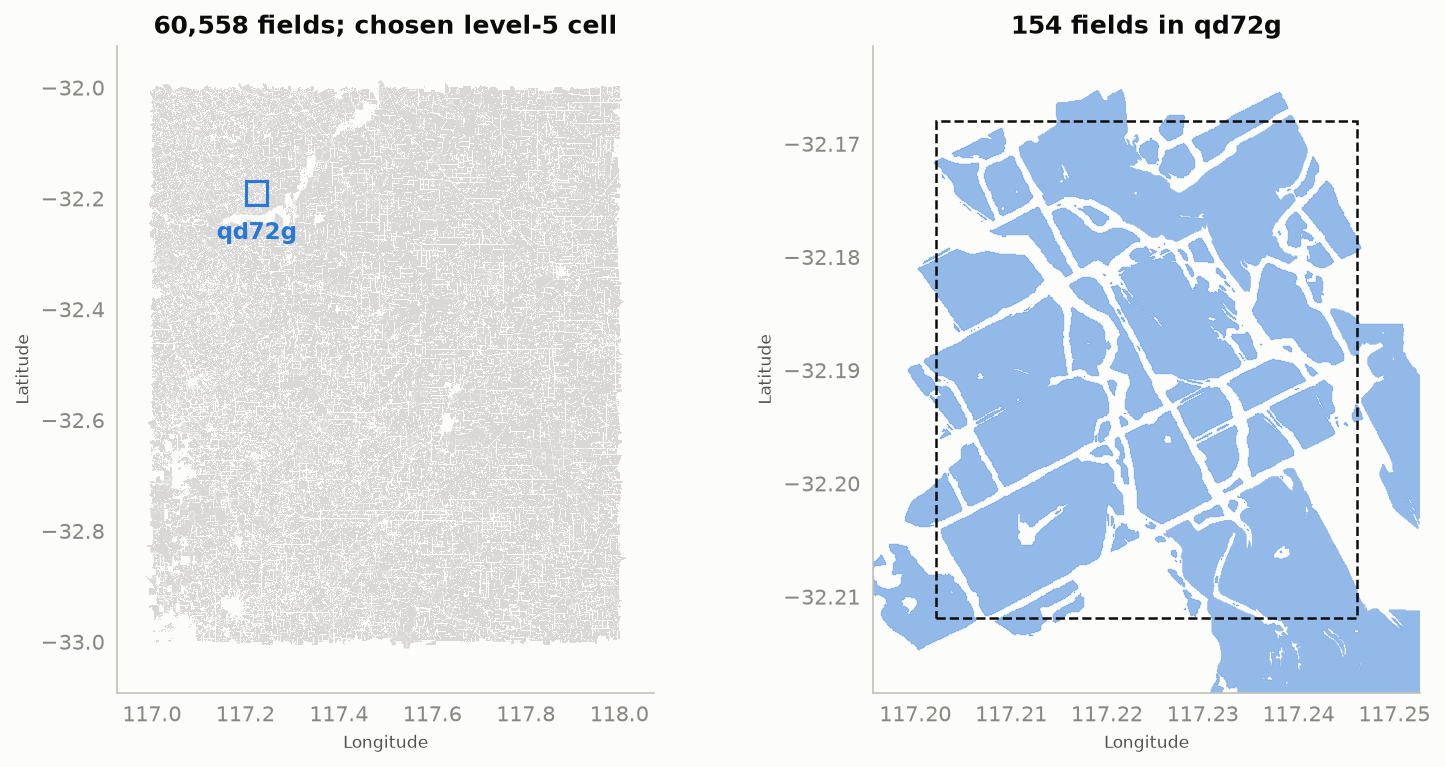

In [3]:
fields["geohash"] = [
    cubesip.geohash.encode(lat=y, lon=x, precision=GEOHASH_PRECISION)
    for x, y in zip(fields["lon"], fields["lat"])
]
stats = fields.groupby("geohash").agg(
    n=("area_ha", "size"), total_ha=("area_ha", "sum"), med_ha=("area_ha", "median")
)
candidates = stats[stats["n"] >= 150].sort_values("total_ha", ascending=False)
CELL = candidates.index[0]
sub = fields[fields["geohash"] == CELL].copy()
b = cubesip.geohash.bbox(CELL)

print(candidates.head().round(1).to_string(), "\n")
print(f"chosen cell: {CELL} - {len(sub)} fields, {sub['area_ha'].sum():.0f} ha in total")
print(f"  lon {b.west:.4f}..{b.east:.4f}, lat {b.south:.4f}..{b.north:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.6), dpi=150)
fig.patch.set_facecolor(SURFACE)
for ax in (ax1, ax2):
    ax.set_facecolor(SURFACE)

# Left: every field, with the chosen cell marked.
fields.plot(ax=ax1, color=INK_MUTED, alpha=0.3, linewidth=0)
ax1.add_patch(
    Rectangle(
        (b.west, b.south), b.east - b.west, b.north - b.south,
        fill=False, edgecolor=ACCENT, linewidth=1.5,
    )
)
ax1.text(
    (b.west + b.east) / 2, b.south - 0.03, CELL, ha="center", va="top",
    color=ACCENT, fontsize=11, fontweight="semibold",
)
ax1.set_xlim(west - 0.06, east + 0.06)
ax1.set_ylim(south - 0.08, north + 0.06)
ax1.set_aspect(1 / np.cos(np.radians(mid_lat)))  # metres look square
ax1.set_title(
    f"{len(fields):,} fields; chosen level-{GEOHASH_PRECISION} cell",
    color=INK_PRIMARY, fontsize=12, fontweight="semibold",
)

# Right: the fields inside the cell.
sub.plot(ax=ax2, color=ACCENT, alpha=0.5, linewidth=0.2, edgecolor=ACCENT)
ax2.add_patch(
    Rectangle(
        (b.west, b.south), b.east - b.west, b.north - b.south,
        fill=False, edgecolor=INK_PRIMARY, linewidth=1.2, linestyle="--",
    )
)
ax2.set_xlim(b.west - 0.15 * (b.east - b.west), b.east + 0.15 * (b.east - b.west))
ax2.set_ylim(b.south - 0.15 * (b.north - b.south), b.north + 0.15 * (b.north - b.south))
ax2.set_aspect(1 / np.cos(np.radians((b.south + b.north) / 2)))
ax2.set_title(
    f"{len(sub)} fields in {CELL}", color=INK_PRIMARY, fontsize=12, fontweight="semibold"
)

for ax in (ax1, ax2):
    ax.set_xlabel("Longitude", color=INK_SECONDARY)
    ax.set_ylabel("Latitude", color=INK_SECONDARY)
    ax.tick_params(colors=INK_MUTED, length=0, pad=6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("bottom", "left"):
        ax.spines[side].set_color(AXIS)
plt.show()


## 3. Sentinel-2 for March–June of 2024 and 2025

One request per year, the period covering the four months. `check` reports what a request
would download without doing it; `run` fetches the data (or serves them from the manifest
cache on a second run). Scenes above 80% cloud cover are left out by the back-end; the
remaining clouds are masked pixel by pixel with SCL in the next step.

In [4]:
requests = {
    year: {
        "driver": "openeo",
        "dataset": DATASET,
        "variables": VARIABLES,
        "geohash": CELL,
        "time": {"start": f"{year}-{MONTHS[0]:02d}-01", "end": f"{year}-{MONTHS[1]:02d}-30"},
        "target_dir": "data",
        "options": {"max_cloud_cover": MAX_CLOUD_COVER},
    }
    for year in YEARS
}
for request in requests.values():
    print(cubesip.check(request), end="\n\n")


cubesip check: openeo SENTINEL2_L2A [B04, B08, SCL] @ qd72g, 2024-03-01 to 2024-06-30
  status : ready to download
  dataset: found, CRS native (set by the source), missing variables: none
  size   : 48.7 MB (estimate, 416x488 px at 10 m, 3 band(s), 20 time step(s) (STAC search), float32)



cubesip check: openeo SENTINEL2_L2A [B04, B08, SCL] @ qd72g, 2025-03-01 to 2025-06-30
  status : ready to download
  dataset: found, CRS native (set by the source), missing variables: none
  size   : 56.0 MB (estimate, 416x488 px at 10 m, 3 band(s), 23 time step(s) (STAC search), float32)



In [5]:
datasets = {}
for year, request in requests.items():
    result = cubesip.run(request)
    origin = "from cache" if result.from_cache else "downloaded"
    print(f"{year}: {origin}, {result.path.name}")
    datasets[year] = result.dataset
crs = native_crs(datasets[YEARS[0]])
print(f"native CRS: {crs}")


Authenticated using refresh token.


2024: downloaded, openeo_SENTINEL2-L2A_qd72g_20240301-20240630_21245e6f.nc


Authenticated using refresh token.


2025: downloaded, openeo_SENTINEL2-L2A_qd72g_20250301-20250630_21245e6f.nc
native CRS: EPSG:32750


## 4. March–June mean NDVI per pixel and its difference

NDVI = (B08 − B04) / (B08 + B04) on the values as downloaded: CDSE stores these bands with
scale 0.0001 and offset 0, so the scale cancels out (as in `ndvi_yearly.py`). Only clear
pixels count — SCL classes 4 (vegetation), 5 (not vegetated) and 6 (water) — and each pixel
is averaged per month first, then over the four months, so a spell with many clear scenes
does not outweigh the others. No scene is dropped as a whole: every pixel uses its own clear
observations.

In [6]:
def seasonal_mean_ndvi(ds: xr.Dataset) -> xr.DataArray:
    """March-June mean NDVI per pixel: monthly means first, then their average."""
    dims = find_dims(ds)
    red, nir, scl = ds["B04"], ds["B08"], ds["SCL"]
    clear = scl.isin(CLEAR_SCL_CLASSES) & ((nir + red) > 0)
    ndvi = ((nir - red) / (nir + red)).where(clear)
    monthly = ndvi.groupby(f"{dims.time}.month").mean(dims.time)
    return monthly.mean("month").compute()  # small grid: load once, use for map and stats


seasonal = {year: seasonal_mean_ndvi(ds) for year, ds in datasets.items()}
dims = find_dims(datasets[YEARS[0]])
delta = seasonal[YEARS[1]] - seasonal[YEARS[0]]
print(delta)


<xarray.DataArray (y: 489, x: 417)> Size: 816kB
array([[-0.06139436, -0.05693477, -0.06504574, ...,  0.01180561,
         0.00612877,  0.00334372],
       [-0.04003093, -0.03154454, -0.05178863, ...,  0.01468009,
         0.00826727,  0.01183268],
       [-0.03816262, -0.02445465, -0.02877817, ...,  0.0142774 ,
         0.00981034,  0.01089858],
       ...,
       [ 0.014219  ,  0.01950178,  0.02302437, ..., -0.00273466,
        -0.0079498 ,  0.00092037],
       [ 0.0108971 ,  0.01932964,  0.02870177, ...,  0.00020203,
         0.0016754 , -0.00062621],
       [ 0.01275709,  0.00384681,  0.01821004, ...,  0.00101158,
         0.00278687,  0.00189641]], shape=(489, 417), dtype=float32)
Coordinates:
  * y        (y) float64 4kB 6.441e+06 6.441e+06 ... 6.436e+06 6.436e+06
  * x        (x) float64 3kB 5.19e+05 5.191e+05 ... 5.232e+05 5.232e+05
    crs      |S1 1B b''
Attributes:
    units:    


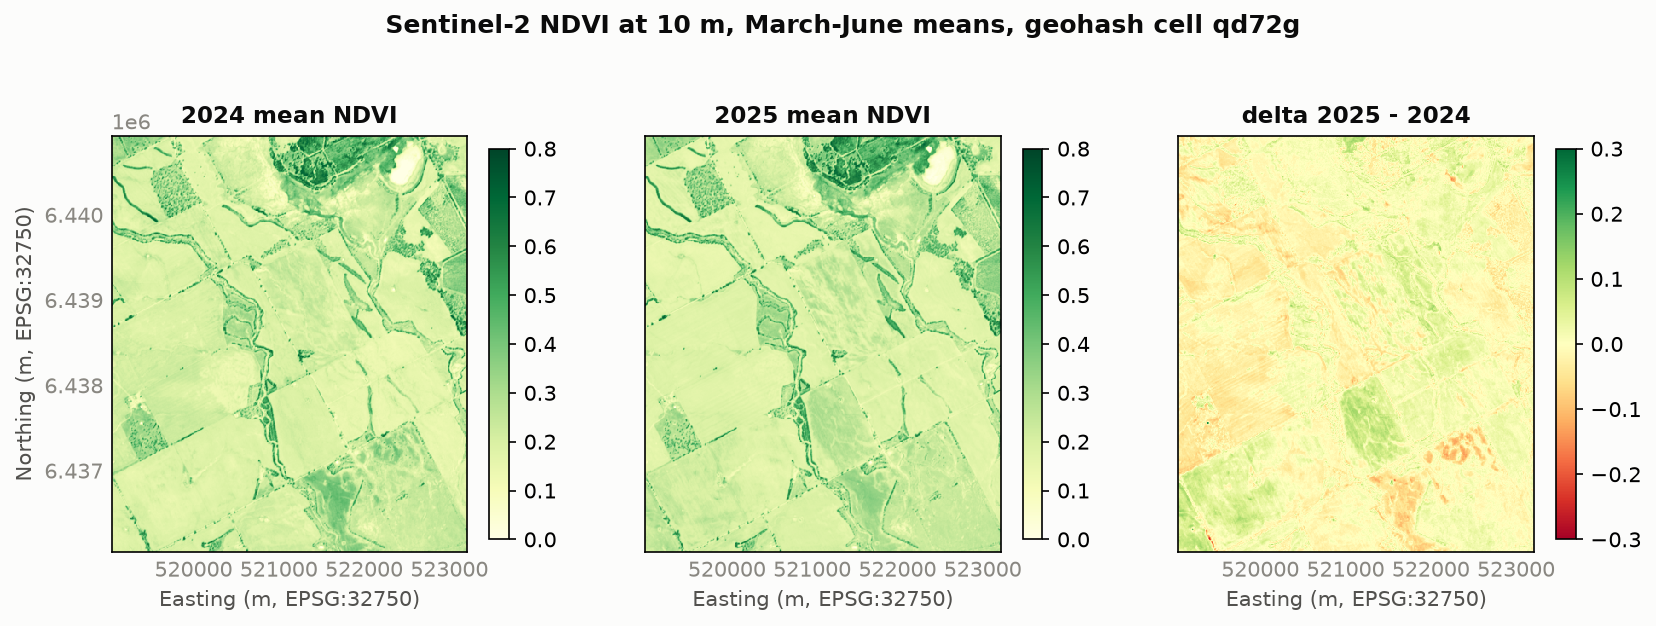

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), dpi=150, sharey=True)
fig.patch.set_facecolor(SURFACE)
top = float(np.ceil(np.nanmax([s.max() for s in seasonal.values()]) / 0.1) * 0.1)
lim = float(np.ceil(np.nanmax(abs(delta)) / 0.05) * 0.05)
for ax, year in zip(axes[:2], YEARS):
    mesh = ax.pcolormesh(
        seasonal[year][dims.x], seasonal[year][dims.y], seasonal[year],
        cmap="YlGn", vmin=0, vmax=top,
    )
    ax.set_title(f"{year} mean NDVI", color=INK_PRIMARY, fontsize=11, fontweight="semibold")
    fig.colorbar(mesh, ax=ax, shrink=0.8)
mesh = axes[2].pcolormesh(
    delta[dims.x], delta[dims.y], delta, cmap="RdYlGn", vmin=-lim, vmax=lim
)
axes[2].set_title(
    f"delta {YEARS[1]} - {YEARS[0]}", color=INK_PRIMARY, fontsize=11, fontweight="semibold"
)
fig.colorbar(mesh, ax=axes[2], shrink=0.8)
for ax in axes:
    ax.set_facecolor(SURFACE)
    ax.set_aspect(1)  # projected metres
    ax.tick_params(colors=INK_MUTED, length=0, pad=4)
    ax.set_xlabel(f"Easting (m, {crs})", color=INK_SECONDARY)
axes[0].set_ylabel(f"Northing (m, {crs})", color=INK_SECONDARY)
fig.suptitle(
    f"Sentinel-2 NDVI at 10 m, March-June means, geohash cell {CELL}",
    color=INK_PRIMARY,
    fontsize=12,
    fontweight="semibold",
)
fig.subplots_adjust(top=0.85)
plt.show()


## 5. From pixels to fields

Each field gets the mean of the pixels it covers: the field polygons are projected onto the
Sentinel-2 grid and rasterised to a field-index image (`all_touched=True`, so a field
narrower than a pixel still gets the pixels it touches), then the seasonal means are
averaged per index. Fields fully covered by clouds in one season come out as NaN.

In [8]:
def grid_transform(da: xr.DataArray) -> Affine:
    """Pixel transform of a regular grid, from its centre coordinates."""
    xs = da[dims.x].values.astype(float)
    ys = da[dims.y].values.astype(float)
    xres = float(np.median(np.diff(xs)))
    yres = float(np.median(np.diff(ys)))  # negative when y runs north to south
    return Affine(xres, 0.0, xs[0] - xres / 2, 0.0, yres, ys[0] - yres / 2)


sub_utm = sub.to_crs(crs)
for year in YEARS:
    da = seasonal[year]
    field_index = rasterize(
        [(geom, i + 1) for i, geom in enumerate(sub_utm.geometry)],
        out_shape=(da.sizes[dims.y], da.sizes[dims.x]),
        transform=grid_transform(da),
        fill=0,
        all_touched=True,
        dtype="int32",
    )
    flat_index, flat_ndvi = field_index.ravel(), da.values.ravel()
    covered = flat_index > 0
    means = pd.Series(flat_ndvi[covered], index=flat_index[covered]).groupby(level=0).mean()
    sub[f"ndvi_{year}"] = means.reindex(range(1, len(sub) + 1)).to_numpy()
sub["delta_ndvi"] = sub[f"ndvi_{YEARS[1]}"] - sub[f"ndvi_{YEARS[0]}"]

cols = [f"ndvi_{YEARS[0]}", f"ndvi_{YEARS[1]}", "delta_ndvi"]
print(sub[cols].describe().round(3), "\n")
print(f"fields with data both years: {sub['delta_ndvi'].notna().sum()} of {len(sub)}")


       ndvi_2024  ndvi_2025  delta_ndvi
count    154.000    154.000     154.000
mean       0.242      0.237      -0.005
std        0.081      0.080       0.022
min        0.124      0.116      -0.072
25%        0.177      0.173      -0.018
50%        0.218      0.216      -0.007
75%        0.288      0.287       0.007
max        0.549      0.532       0.063 

fields with data both years: 154 of 154


## 6. Choropleth of the delta

One colour per field: green marks a higher March–June NDVI in 2025 than in 2024, red a lower
one. The map is drawn in the Sentinel-2 CRS and saved to `data/`.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Choropleth: data\fields_ndvi_delta_2025_minus_2024_qd72g.png


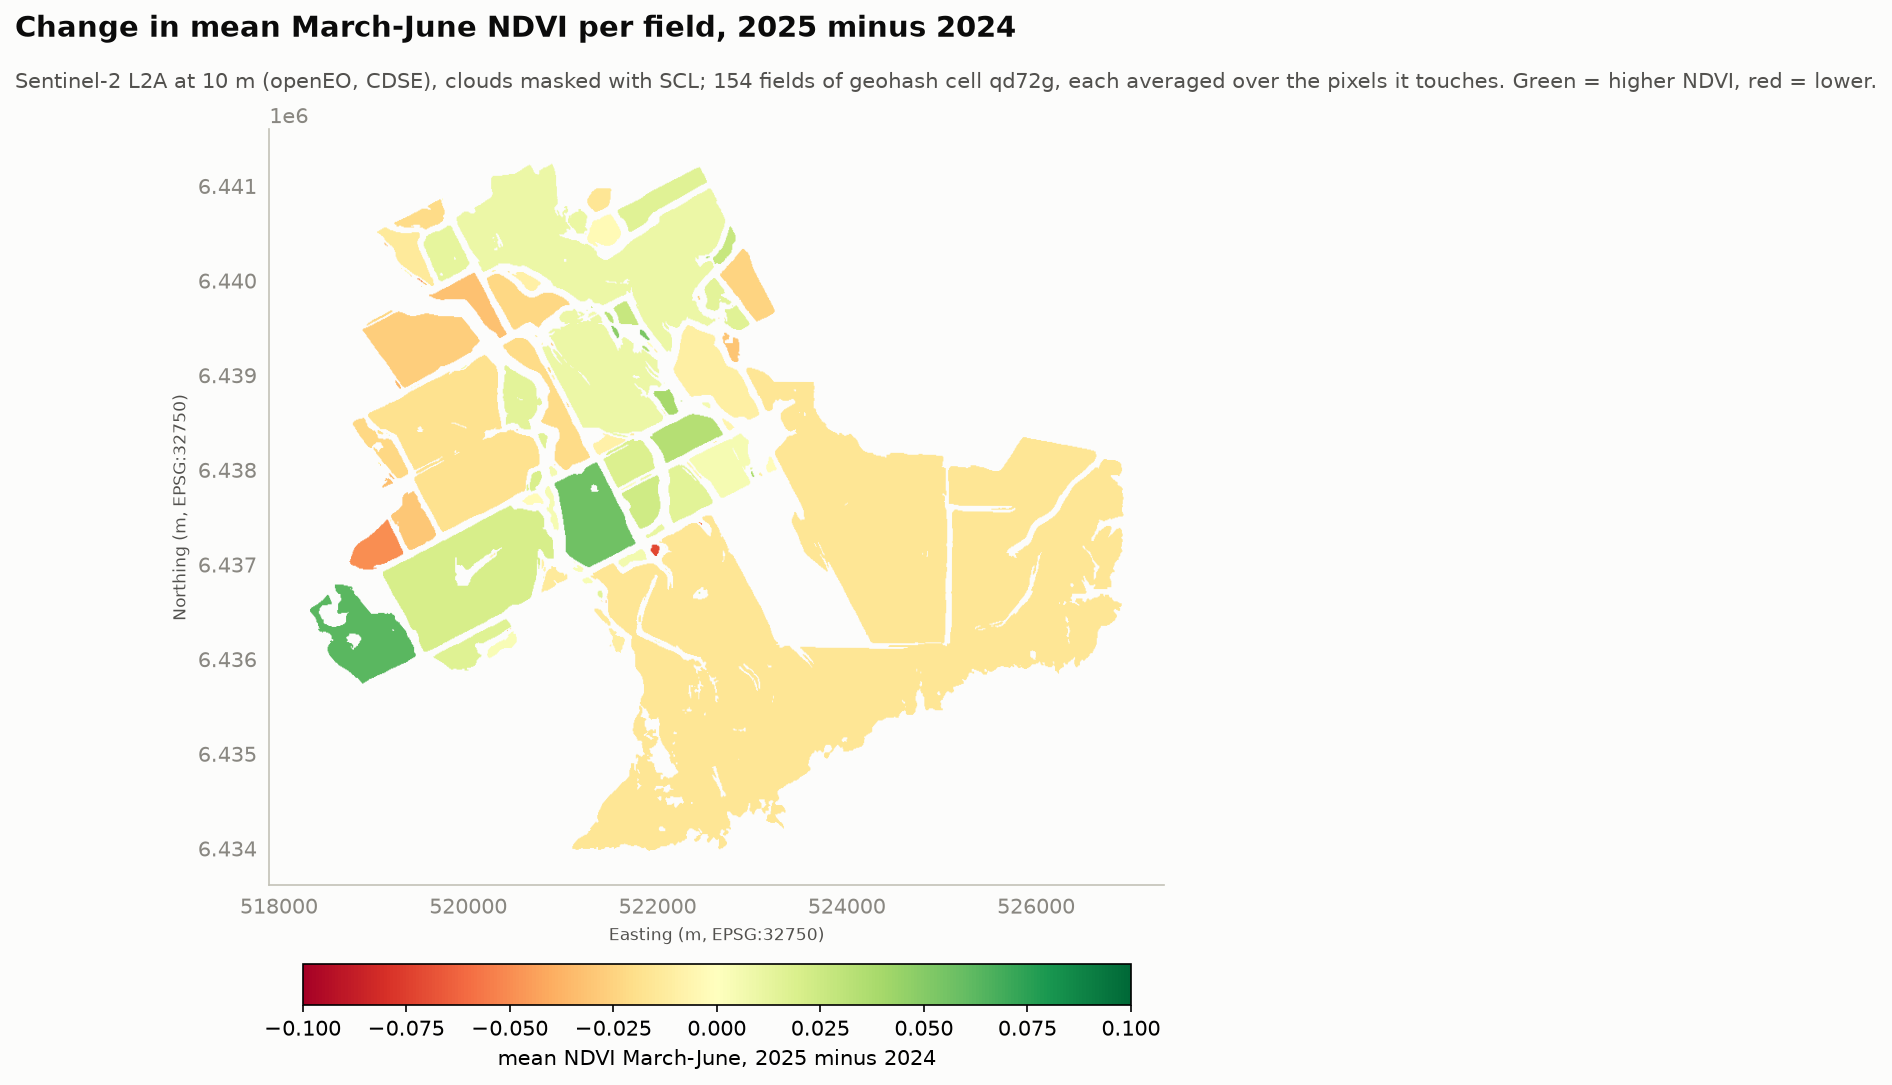

In [9]:
plot_fields = sub.to_crs(crs)
lim = float(np.ceil(np.nanmax(abs(sub["delta_ndvi"])) / 0.05) * 0.05)
fig, ax = plt.subplots(figsize=(9.5, 8.5), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
plot_fields.plot(
    column="delta_ndvi",
    ax=ax,
    cmap="RdYlGn",
    vmin=-lim,
    vmax=lim,
    linewidth=0,
    legend=True,
    legend_kwds={
        "label": f"mean NDVI March-June, {YEARS[1]} minus {YEARS[0]}",
        "orientation": "horizontal",
        "shrink": 0.75,
        "pad": 0.08,
    },
)
ax.set_aspect(1)
ax.set_xlabel(f"Easting (m, {crs})", color=INK_SECONDARY)
ax.set_ylabel(f"Northing (m, {crs})", color=INK_SECONDARY)
ax.tick_params(colors=INK_MUTED, length=0, pad=6)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("bottom", "left"):
    ax.spines[side].set_color(AXIS)
fig.subplots_adjust(top=0.88)
fig.text(
    0.02,
    0.97,
    f"Change in mean March-June NDVI per field, {YEARS[1]} minus {YEARS[0]}",
    va="top",
    color=INK_PRIMARY,
    fontsize=14,
    fontweight="semibold",
)
fig.text(
    0.02,
    0.925,
    f"Sentinel-2 L2A at 10 m (openEO, CDSE), clouds masked with SCL; {len(sub)} fields of "
    f"geohash cell {CELL}, each averaged over the pixels it touches. "
    "Green = higher NDVI, red = lower.",
    va="top",
    color=INK_SECONDARY,
    fontsize=10,
)
png_path = Path(f"data/fields_ndvi_delta_{YEARS[1]}_minus_{YEARS[0]}_{CELL}.png")
fig.savefig(png_path, facecolor=SURFACE, bbox_inches="tight", pad_inches=0.2)
print(f"Choropleth: {png_path}")
plt.show()
